# Tugas 2 - Klasifikasi Gambar Pakaian dengan Convolutional Neural Network (TensorFlow / Keras)

| Nama | NRP |
|------|-----|
| Muhammad Nazwar Fakhrurrozy | 5054251040 |

## Deskripsi Tugas
Pada tugas ini, kita akan menggunakan Fashion-MNIST Dataset. Dataset bisa diakses melalui link berikut:\
https://www.kaggle.com/datasets/zalando-research/fashionmnist

Dataset berisi 70.000 gambar grayscale berukuran 28×28 piksel yang terbagi ke dalam 10 kelas pakaian (T-shirt/top, Trouser, Pullover, Dress, Coat, Sandal, Shirt, Sneaker, Bag, Ankle boot). Tujuan utama dari tugas ini adalah membangun model Convolutional Neural Network (CNN) menggunakan **TensorFlow / Keras** untuk mengklasifikasikan jenis pakaian, lalu membandingkannya dengan ANN biasa.

Disarankan menggunakan GPU (Google Colab: *Runtime → Change runtime type → T4 GPU*, atau Kaggle Notebook).

Langkah-langkah yang harus dilakukan antara lain:
1. Persiapan Dataset dan Eksplorasi Awal
   - Memuat dataset, melihat contoh gambar, dan distribusi label.
2. Preprocessing
   - Memproses data gambar agar siap digunakan oleh model.
3. Eksperimen Model
   - Bangun model ANN, CNN sederhana, dan CNN dengan Batch Normalization dan Dropout.
4. Evaluasi Model
   - Hitung metrik evaluasi, visualisasikan hasilnya, dan simpan model terbaik.
5. Analisis dan Kesimpulan
   - Bandingkan hasil ketiga model dan berikan kesimpulan.

# 1. Persiapan Dataset dan Eksplorasi Awal

In [61]:
# Import library yang dibutuhkan (pandas, numpy, matplotlib, seaborn, sklearn, tensorflow, dll).
# Set random seed dengan tf.keras.utils.set_random_seed(42).
# Cek apakah GPU tersedia dengan tf.config.list_physical_devices("GPU").
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_recall_fscore_support
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix

import tensorflow as tf

tf.keras.utils.set_random_seed(42)

gpu_devices = tf.config.list_physical_devices("GPU")
print(gpu_devices)

[]


In [26]:
# Load file fashion-mnist_train.csv dan fashion-mnist_test.csv.
# Setiap baris berisi 1 kolom label dan 784 kolom piksel (28×28) bernilai 0-255.
# Tampilkan ukuran data train dan test.
train_df = pd.read_csv("fashion-mnist_train.csv")
test_df = pd.read_csv("fashion-mnist_test.csv")

print(train_df.shape)
print(test_df.shape)

(60000, 785)
(10000, 785)


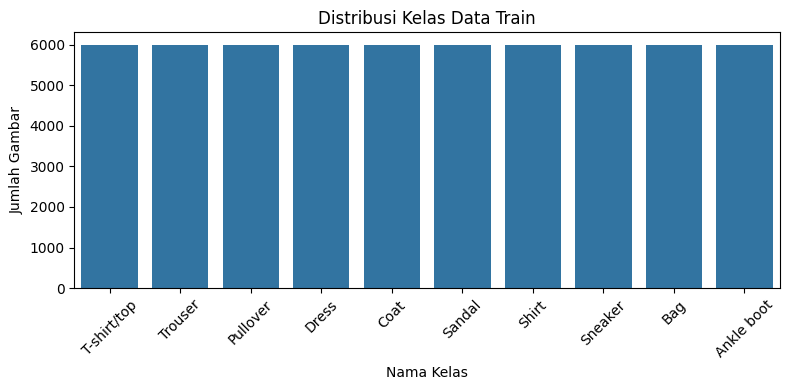

In [27]:
# Buat list atau dictionary yang memetakan label angka (0-9) ke nama kelas.
# Tampilkan distribusi kelas pada train set dalam bentuk bar plot.
class_labels = {
    0: "T-shirt/top",
    1: "Trouser",
    2: "Pullover",
    3: "Dress",
    4: "Coat",
    5: "Sandal",
    6: "Shirt",
    7: "Sneaker",
    8: "Bag",
    9: "Ankle boot"
}

plt.figure(figsize=(8, 4))
sns.countplot(x="label", data=train_df)
plt.xticks(ticks=range(10), labels=[class_labels[i] for i in range(10)], rotation=45)
plt.title("Distribusi Kelas Data Train")
plt.xlabel("Nama Kelas")
plt.ylabel("Jumlah Gambar")
plt.tight_layout()
plt.show()

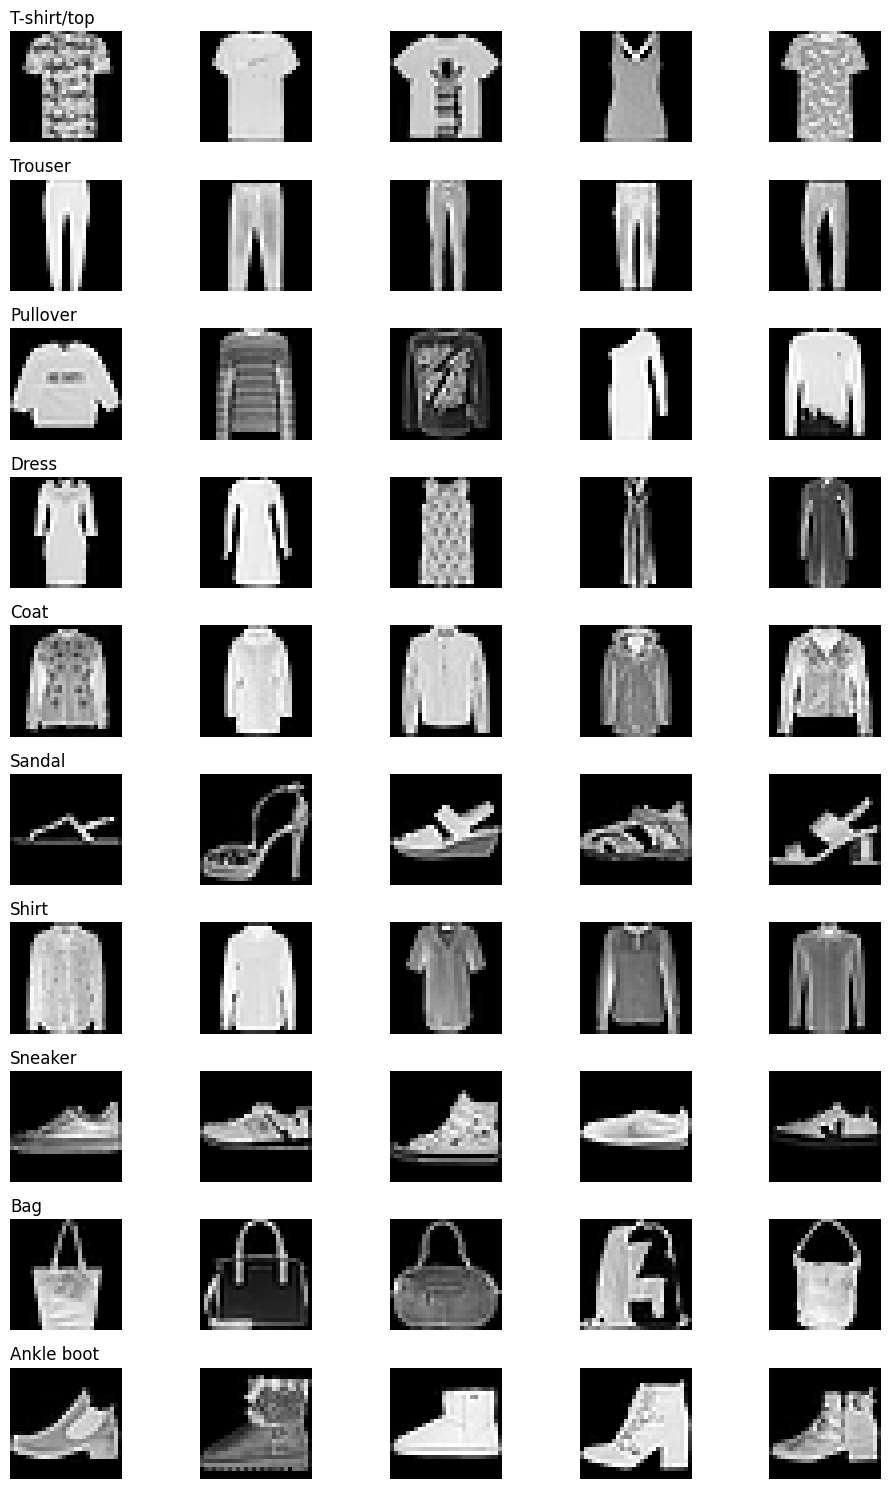

In [28]:
# Tampilkan contoh gambar dari setiap kelas (misalnya grid 10 kelas × 5 gambar) beserta nama kelasnya.
# Kelas mana saja yang secara visual terlihat mirip?
fig, axes = plt.subplots(10, 5, figsize=(10, 15))

for label_idx in range(10):
    samples = train_df[train_df["label"] == label_idx].iloc[:5]
    for img_idx in range(5):
        pixels = samples.iloc[img_idx, 1:].values.reshape(28, 28)
        ax = axes[label_idx, img_idx]
        ax.imshow(pixels, cmap="gray")
        ax.axis("off")
        if img_idx == 0:
            ax.set_title(class_labels[label_idx], loc="left")

plt.tight_layout()
plt.show()

- Pullover, Coat, dan Shirt
Ketiga kelas ini sangat mirip karena sama-sama merupakan pakaian atasan berlengan panjang dengan kontur tubuh atas yang identik pada resolusi rendah 28x28 piksel.

- T-shirt/top dan Shirt
Keduanya memiliki potongan bagian bahu dan lengan yang mirip, terutama apabila kemeja memiliki lengan pendek atau kancing kerah yang samar pada citra grayskail.

- Dress dan Coat
Beberapa sampel Dress berpotongan lurus atau Coat berukuran panjang memiliki siluet memanjang yang hampir sama dari bagian atas hingga bawah.

- Sneaker dan Ankle boot
Keduanya memiliki siluet samping alas kaki yang menutup seluruh bagian kaki, sehingga garis batas tumit dan pergelangan kaki sering kali terlihat seragam.

## Lakukan Exploratory Data Analysis (EDA) tambahan yang diperlukan.

# 2. Preprocessing

Model yang berbeda membutuhkan bentuk input yang berbeda. Di TensorFlow/Keras, urutan dimensi gambar adalah **(batch, tinggi, lebar, channel)**:

| Model | Bentuk input |
|---|---|
| ANN | `(N, 784)` |
| CNN | `(N, 28, 28, 1)` |

In [29]:
print(train_df.isnull().sum().sum())
print(test_df.isnull().sum().sum())
print(train_df.drop('label', axis=1).min().min(), train_df.drop('label', axis=1).max().max())

0
0
0 255


In [30]:
# Pisahkan label (y) dan piksel (X) untuk data train dan test.
y_raw = train_df['label'].values
X_raw = train_df.drop('label', axis=1).values

y_test = test_df['label'].values
X_test_raw = test_df.drop('label', axis=1).values

In [31]:
# Normalisasi nilai piksel ke rentang 0-1 (bagi dengan 255).
X_norm = X_raw / 255.0
X_test_norm = X_test_raw / 255.0

In [32]:
# Bagi data train menjadi train set dan validation set (misalnya 90:10) dengan stratify=y.
# Test set dari file fashion-mnist_test.csv hanya digunakan untuk evaluasi akhir.
X_train, X_val, y_train, y_val = train_test_split(
    X_norm, y_raw, test_size=0.10, random_state=42, stratify=y_raw
)

In [33]:
# Ubah bentuk data sesuai kebutuhan model (lihat tabel di atas), pastikan bertipe float32.
# Contoh untuk CNN: X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype("float32")
X_train_ann = X_train.astype('float32')
X_val_ann = X_val.astype('float32')
X_test_ann = X_test_norm.astype('float32')

X_train_cnn = X_train.reshape(-1, 28, 28, 1).astype('float32')
X_val_cnn = X_val.reshape(-1, 28, 28, 1).astype('float32')
X_test_cnn = X_test_norm.reshape(-1, 28, 28, 1).astype('float32')

print(X_train_ann.shape, X_val_ann.shape, X_test_ann.shape)
print(X_train_cnn.shape, X_val_cnn.shape, X_test_cnn.shape)

(54000, 784) (6000, 784) (10000, 784)
(54000, 28, 28, 1) (6000, 28, 28, 1) (10000, 28, 28, 1)


# 3. Eksperimen Model

## 3.1 ANN (Baseline)

Gambar di-flatten menjadi vektor 784 nilai, lalu diproses oleh ANN biasa. Karena ini klasifikasi multikelas, gunakan **10 neuron output dengan aktivasi Softmax** dan **`sparse_categorical_crossentropy`** sebagai loss function (label berupa angka 0-9).

Contoh arsitektur: `Input(784) → Dense(256, ReLU) → Dense(128, ReLU) → Dense(10, Softmax)`

In [50]:
# Definisikan arsitektur ANN menggunakan keras.Sequential.
# Tampilkan ringkasan model beserta jumlah parameternya dengan model.summary().
model_ann = tf.keras.Sequential([
    tf.keras.Input(shape=(784,)),
    tf.keras.layers.Dense(256, activation='relu'),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_ann.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 256)            │       200,960 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 235,146 (918.54 KB)

 Trainable params: 235,146 (918.54 KB)

 Non-trainable params: 0 (0.00 B)

In [51]:
# Compile model dengan optimizer, loss="sparse_categorical_crossentropy", dan metrics=["accuracy"].
# Latih model dengan model.fit() menggunakan validation_data, simpan hasilnya ke variabel history.
model_ann.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_ann = model_ann.fit(
    X_train_ann,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_ann, y_val)
)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8199 - loss: 0.5024 - val_accuracy: 0.8573 - val_loss: 0.3933
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8651 - loss: 0.3713 - val_accuracy: 0.8638 - val_loss: 0.3669
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8788 - loss: 0.3315 - val_accuracy: 0.8683 - val_loss: 0.3511
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8884 - loss: 0.3049 - val_accuracy: 0.8695 - val_loss: 0.3450
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8945 - loss: 0.2869 - val_accuracy: 0.8717 - val_loss: 0.3332
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.8999 - loss: 0.2693 - val_accuracy: 0.8807 - val_loss: 0.3224
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9055 - loss: 0.2549 - val_accuracy: 0.8740 - val_loss: 0.3413
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 2s 2ms/step - accuracy: 0.9096 - loss: 0.2430 - val_accuracy: 0.

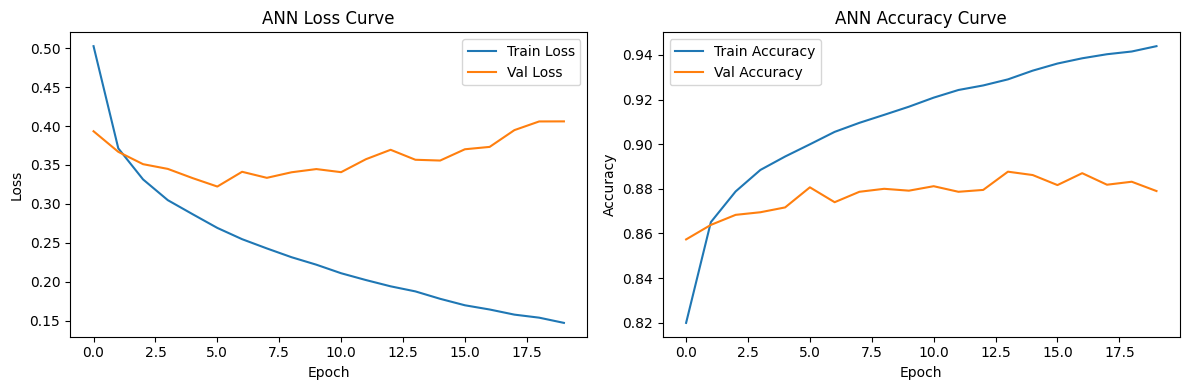

In [52]:
# Tampilkan learning curve (loss dan accuracy) train vs validation.
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_ann.history['loss'], label='Train Loss')
axes[0].plot(history_ann.history['val_loss'], label='Val Loss')
axes[0].set_title('ANN Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history_ann.history['accuracy'], label='Train Accuracy')
axes[1].plot(history_ann.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('ANN Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [53]:
# Lakukan prediksi pada test set. model.predict() menghasilkan probabilitas 10 kelas,
# ambil kelas dengan probabilitas terbesar menggunakan argmax(axis=1). Simpan hasil prediksi label.
y_pred_prob_ann = model_ann.predict(X_test_ann)
y_pred_ann = np.argmax(y_pred_prob_ann, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 751us/step


## 3.2 CNN Sederhana

Bangun CNN dengan **2 blok konvolusi**, masing-masing terdiri dari Conv2D (ReLU) → MaxPooling, lalu dilanjutkan Flatten dan Dense.

Contoh arsitektur: `[Conv2D(32, 3×3, ReLU) → MaxPooling2D(2×2)] → [Conv2D(64, 3×3, ReLU) → MaxPooling2D(2×2)] → Flatten → Dense(128, ReLU) → Dense(10, Softmax)`

In [54]:
# Definisikan arsitektur CNN sederhana menggunakan layers.Conv2D, layers.MaxPooling2D, layers.Flatten, dan layers.Dense.
# Gunakan keras.Input(shape=(28, 28, 1)) sebagai layer pertama.
# Tampilkan ringkasan model beserta jumlah parameternya.
# Hitung secara manual ukuran output setiap layer konvolusi dan pooling menggunakan rumus (W - K + 2P) / S + 1,
# lalu cocokkan dengan kolom "Output Shape" pada model.summary(). (padding="valid" berarti P = 0, padding="same" menjaga ukuran tetap)
model_cnn = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_cnn.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,034 (879.04 KB)

 Trainable params: 225,034 (879.04 KB)

 Non-trainable params: 0 (0.00 B)

Perhitungan manual ukuran output tiap layer:

Rumus umum: (W - K + 2P) / S + 1 dengan P = 0 (padding valid) dan S = 1 untuk konvolusi, S = 2 untuk pooling.

    - Conv2D Pertama: (28 - 3 + 0) / 1 + 1 = 26. Bentuk output adalah (26, 26, 32).

    - MaxPooling2D Pertama: (26 - 2 + 0) / 2 + 1 = 13. Bentuk output adalah (13, 13, 32).

    - Conv2D Kedua: (13 - 3 + 0) / 1 + 1 = 11. Bentuk output adalah (11, 11, 64).

    - MaxPooling2D Kedua: (11 - 2 + 0) / 2 + 1 = 5. Bentuk output adalah (5, 5, 64).

    - Flatten: 5 x 5 x 64 = 1600. Bentuk output adalah (1600,).

    - Dense Pertama: 128 neuron. Bentuk output adalah (128,).

    - Dense Kedua: 10 neuron. Bentuk output adalah (10,).

Hasil perhitungan manual ini sesuai dengan Output Shape pada model summary.

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8205 - loss: 0.4988 - val_accuracy: 0.8618 - val_loss: 0.3844
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8786 - loss: 0.3327 - val_accuracy: 0.8730 - val_loss: 0.3469
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8958 - loss: 0.2855 - val_accuracy: 0.8838 - val_loss: 0.3142
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9073 - loss: 0.2525 - val_accuracy: 0.8910 - val_loss: 0.2915
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9176 - loss: 0.2251 - val_accuracy: 0.8977 - val_loss: 0.2749
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9263 - loss: 0.2012 - val_accuracy: 0.9040 - val_loss: 0.2621
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9349 - loss: 0.1798 - val_accuracy: 0.9075 - val_loss: 0.2581
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9425 - loss: 0.1594 - val_accuracy: 0.

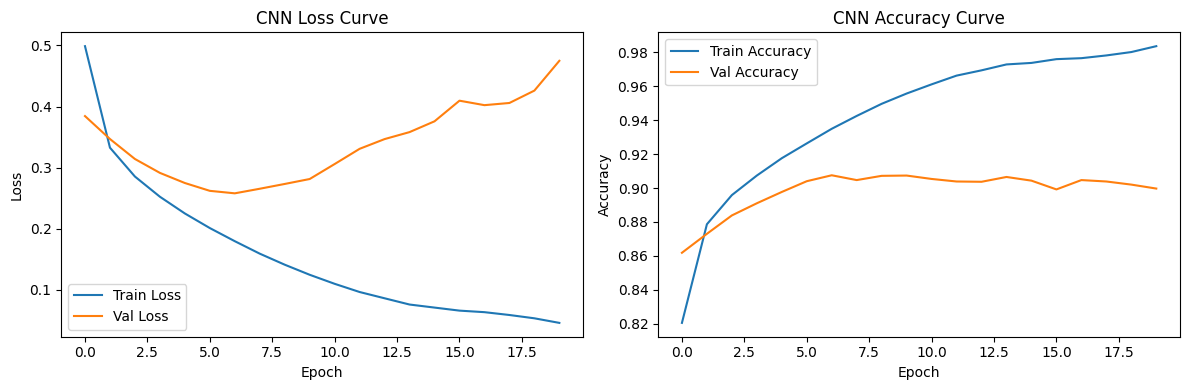

In [55]:
# Latih model dengan pengaturan yang sama seperti 3.1 agar perbandingan adil.
# Tampilkan learning curve train vs validation.
model_cnn.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_cnn = model_cnn.fit(
    X_train_cnn,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_cnn, y_val)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_cnn.history['loss'], label='Train Loss')
axes[0].plot(history_cnn.history['val_loss'], label='Val Loss')
axes[0].set_title('CNN Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history_cnn.history['accuracy'], label='Train Accuracy')
axes[1].plot(history_cnn.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('CNN Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [56]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_prob_cnn = model_cnn.predict(X_test_cnn)
y_pred_cnn = np.argmax(y_pred_prob_cnn, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step


## 3.3 CNN dengan Batch Normalization dan Dropout

Gunakan arsitektur CNN pada 3.2, lalu tambahkan **Batch Normalization** setelah setiap layer konvolusi dan **Dropout** sebelum layer output.

In [57]:
# Definisikan arsitektur CNN dengan Batch Normalization dan Dropout.
# Urutan yang umum: Conv2D (tanpa activation) -> layers.BatchNormalization() -> layers.Activation("relu") -> MaxPooling2D.
# Tambahkan layers.Dropout(rate) sebelum layer output.
# Tampilkan ringkasan model beserta jumlah parameternya.
model_bn_do = tf.keras.Sequential([
    tf.keras.Input(shape=(28, 28, 1)),
    tf.keras.layers.Conv2D(32, kernel_size=(3, 3)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Conv2D(64, kernel_size=(3, 3)),
    tf.keras.layers.BatchNormalization(),
    tf.keras.layers.Activation('relu'),
    tf.keras.layers.MaxPooling2D(pool_size=(2, 2)),
    tf.keras.layers.Flatten(),
    tf.keras.layers.Dense(128, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(10, activation='softmax')
])

model_bn_do.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation (Activation)         │ (None, 26, 26, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ activation_1 (Activation)       │ (None, 11, 11, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 1600)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 128)            │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 225,418 (880.54 KB)

 Trainable params: 225,226 (879.79 KB)

 Non-trainable params: 192 (768.00 B)

Epoch 1/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 11s 12ms/step - accuracy: 0.7889 - loss: 0.5911 - val_accuracy: 0.8602 - val_loss: 0.3813
Epoch 2/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 12ms/step - accuracy: 0.8481 - loss: 0.4198 - val_accuracy: 0.8748 - val_loss: 0.3371
Epoch 3/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 10s 11ms/step - accuracy: 0.8654 - loss: 0.3735 - val_accuracy: 0.8890 - val_loss: 0.3126
Epoch 4/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8776 - loss: 0.3404 - val_accuracy: 0.8880 - val_loss: 0.3095
Epoch 5/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8856 - loss: 0.3157 - val_accuracy: 0.8830 - val_loss: 0.3177
Epoch 6/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8922 - loss: 0.2969 - val_accuracy: 0.8897 - val_loss: 0.3014
Epoch 7/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.8991 - loss: 0.2778 - val_accuracy: 0.8883 - val_loss: 0.3162
Epoch 8/20
844/844 ━━━━━━━━━━━━━━━━━━━━ 9s 11ms/step - accuracy: 0.9037 - loss: 0.2663 - val_a

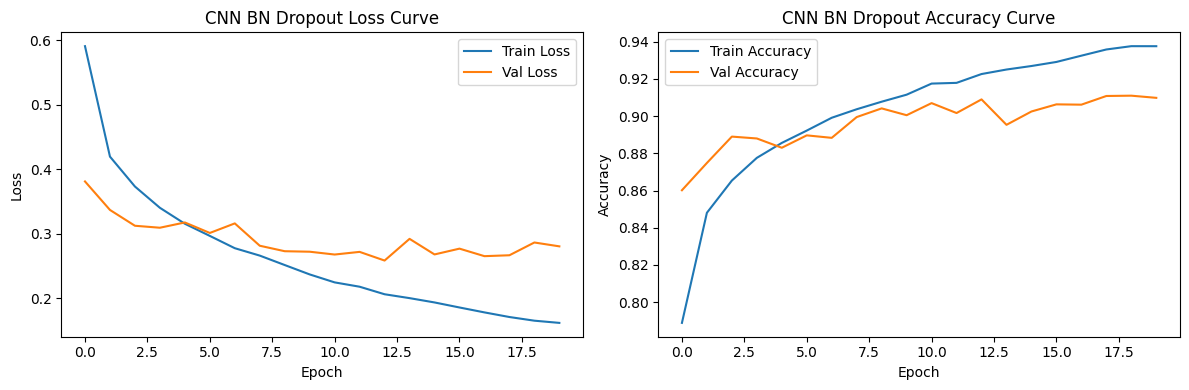

In [58]:
# Latih model dengan pengaturan yang sama seperti 3.2.
# Tampilkan learning curve train vs validation.
# Perhatikan selisih antara train dan validation dibandingkan dengan model 3.2.
model_bn_do.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

history_bn_do = model_bn_do.fit(
    X_train_cnn,
    y_train,
    epochs=20,
    batch_size=64,
    validation_data=(X_val_cnn, y_val)
)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history_bn_do.history['loss'], label='Train Loss')
axes[0].plot(history_bn_do.history['val_loss'], label='Val Loss')
axes[0].set_title('CNN BN Dropout Loss Curve')
axes[0].set_xlabel('Epoch')
axes[0].set_ylabel('Loss')
axes[0].legend()

axes[1].plot(history_bn_do.history['accuracy'], label='Train Accuracy')
axes[1].plot(history_bn_do.history['val_accuracy'], label='Val Accuracy')
axes[1].set_title('CNN BN Dropout Accuracy Curve')
axes[1].set_xlabel('Epoch')
axes[1].set_ylabel('Accuracy')
axes[1].legend()

plt.tight_layout()
plt.show()

In [59]:
# Lakukan prediksi pada test set dan simpan hasil prediksi label.
y_pred_prob_bn_do = model_bn_do.predict(X_test_cnn)
y_pred_bn_do = np.argmax(y_pred_prob_bn_do, axis=1)

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


# 4. Evaluasi Model

In [62]:
# Tampilkan metrik evaluasi untuk setiap model: Accuracy, Precision, Recall, dan F1-Score (macro average),
# beserta jumlah parameter setiap model. Sajikan dalam satu tabel perbandingan.
def evaluate_model(name, y_true, y_pred, model):
    acc = accuracy_score(y_true, y_pred)
    prec, rec, f1, _ = precision_recall_fscore_support(y_true, y_pred, average='macro')
    params = model.count_params()
    return {
        'Model': name,
        'Accuracy': round(acc, 4),
        'Precision': round(prec, 4),
        'Recall': round(rec, 4),
        'F1-Score': round(f1, 4),
        'Total Params': params
    }

metrics_list = [
    evaluate_model('ANN Baseline', y_test, y_pred_ann, model_ann),
    evaluate_model('CNN Sederhana', y_test, y_pred_cnn, model_cnn),
    evaluate_model('CNN BN + Dropout', y_test, y_pred_bn_do, model_bn_do)
]

comparison_df = pd.DataFrame(metrics_list)
print(comparison_df.to_string(index=False))

           Model  Accuracy  Precision  Recall  F1-Score  Total Params
    ANN Baseline    0.8813     0.8839  0.8813    0.8817        235146
   CNN Sederhana    0.9097     0.9101  0.9097    0.9095        225034
CNN BN + Dropout    0.9124     0.9132  0.9124    0.9127        225418


In [63]:
# Tampilkan classification report (metrik per kelas) untuk model terbaik.
target_names = [class_labels[i] for i in range(10)]
print(classification_report(y_test, y_pred_bn_do, target_names=target_names))

              precision    recall  f1-score   support

 T-shirt/top       0.85      0.85      0.85      1000
     Trouser       0.99      0.98      0.99      1000
    Pullover       0.89      0.85      0.87      1000
       Dress       0.93      0.91      0.92      1000
        Coat       0.87      0.86      0.87      1000
      Sandal       0.99      0.97      0.98      1000
       Shirt       0.73      0.77      0.75      1000
     Sneaker       0.96      0.95      0.96      1000
         Bag       0.97      0.99      0.98      1000
  Ankle boot       0.95      0.97      0.96      1000

    accuracy                           0.91     10000
   macro avg       0.91      0.91      0.91     10000
weighted avg       0.91      0.91      0.91     10000



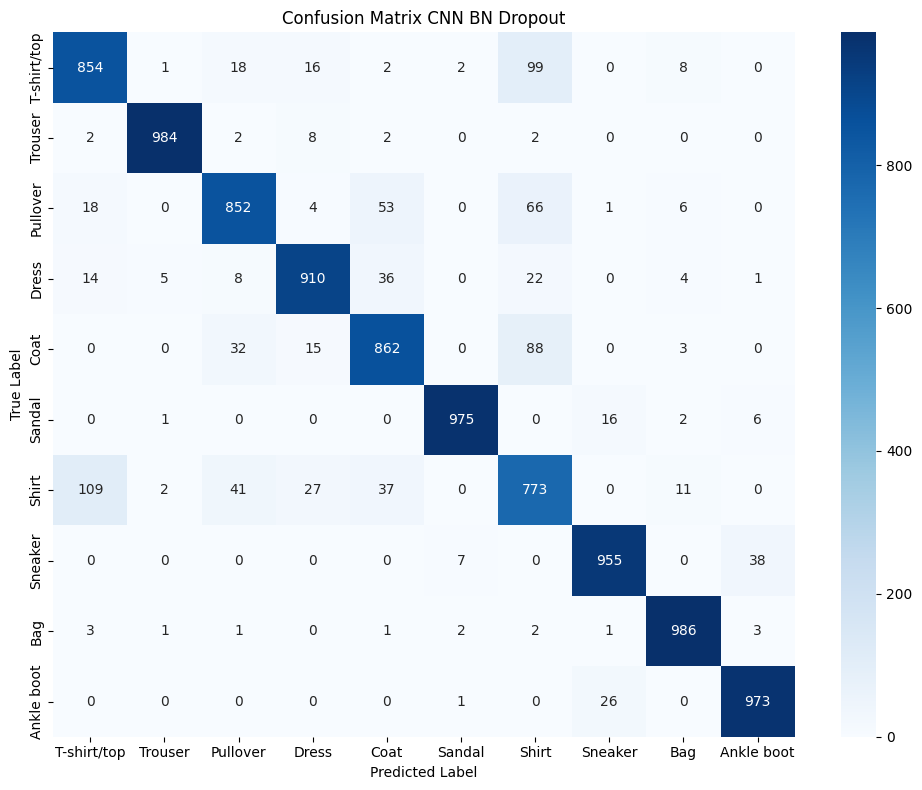

In [64]:
# Tampilkan Confusion Matrix 10×10 model terbaik dalam bentuk heatmap, gunakan nama kelas sebagai label sumbu.
# Pasangan kelas mana yang paling sering tertukar?
cm = confusion_matrix(y_test, y_pred_bn_do)
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=target_names, yticklabels=target_names)
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Confusion Matrix CNN BN Dropout')
plt.tight_layout()
plt.show()

Pasangan kelas yang paling sering tertukar adalah Shirt dengan T-shirt/top, Shirt dengan Pullover, serta Shirt dengan Coat. Hal ini terjadi karena produk pakaian atasan tersebut memiliki bentuk geometris dan kontur siluet yang sangat serupa pada resolusi gambar 28x28 piksel.

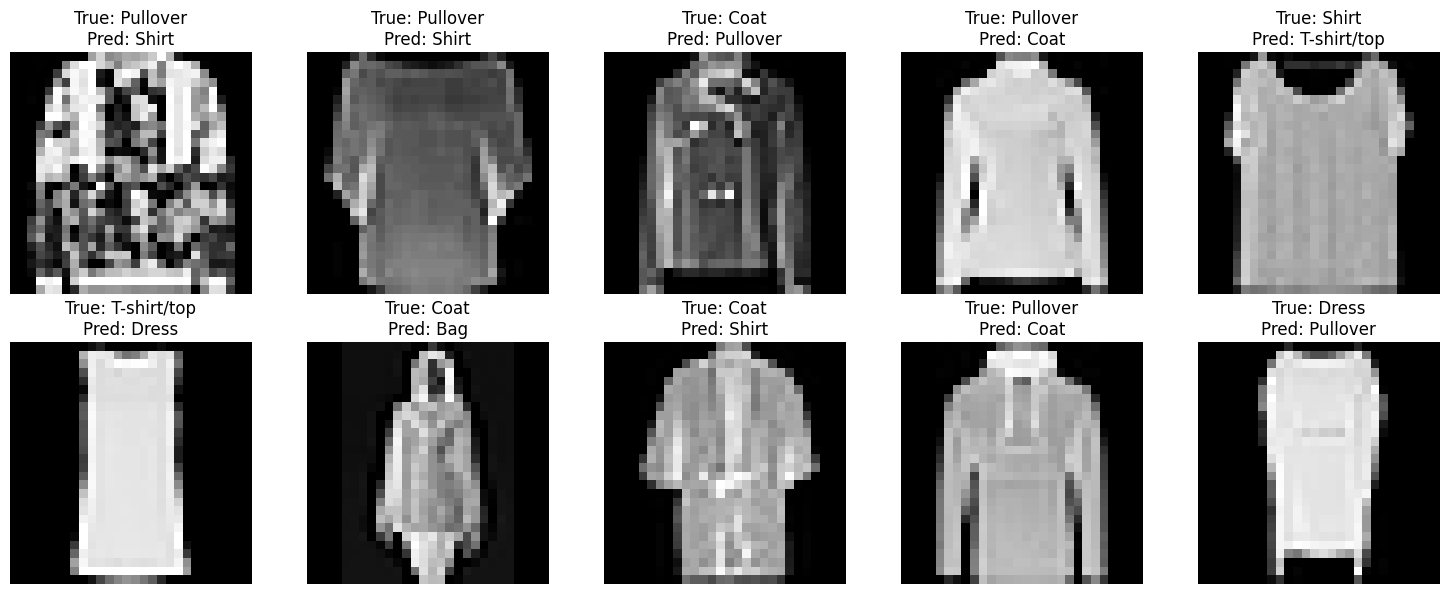

In [65]:
# Tampilkan beberapa contoh gambar yang salah diklasifikasikan oleh model terbaik,
# beserta label asli dan label prediksinya.
misclassified_idx = np.where(y_pred_bn_do != y_test)[0]

fig, axes = plt.subplots(2, 5, figsize=(15, 6))
axes = axes.ravel()

for i in range(10):
    idx = misclassified_idx[i]
    axes[i].imshow(X_test_cnn[idx].reshape(28, 28), cmap='gray')
    true_label = class_labels[y_test[idx]]
    pred_label = class_labels[y_pred_bn_do[idx]]
    axes[i].set_title(f'True: {true_label}\nPred: {pred_label}')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


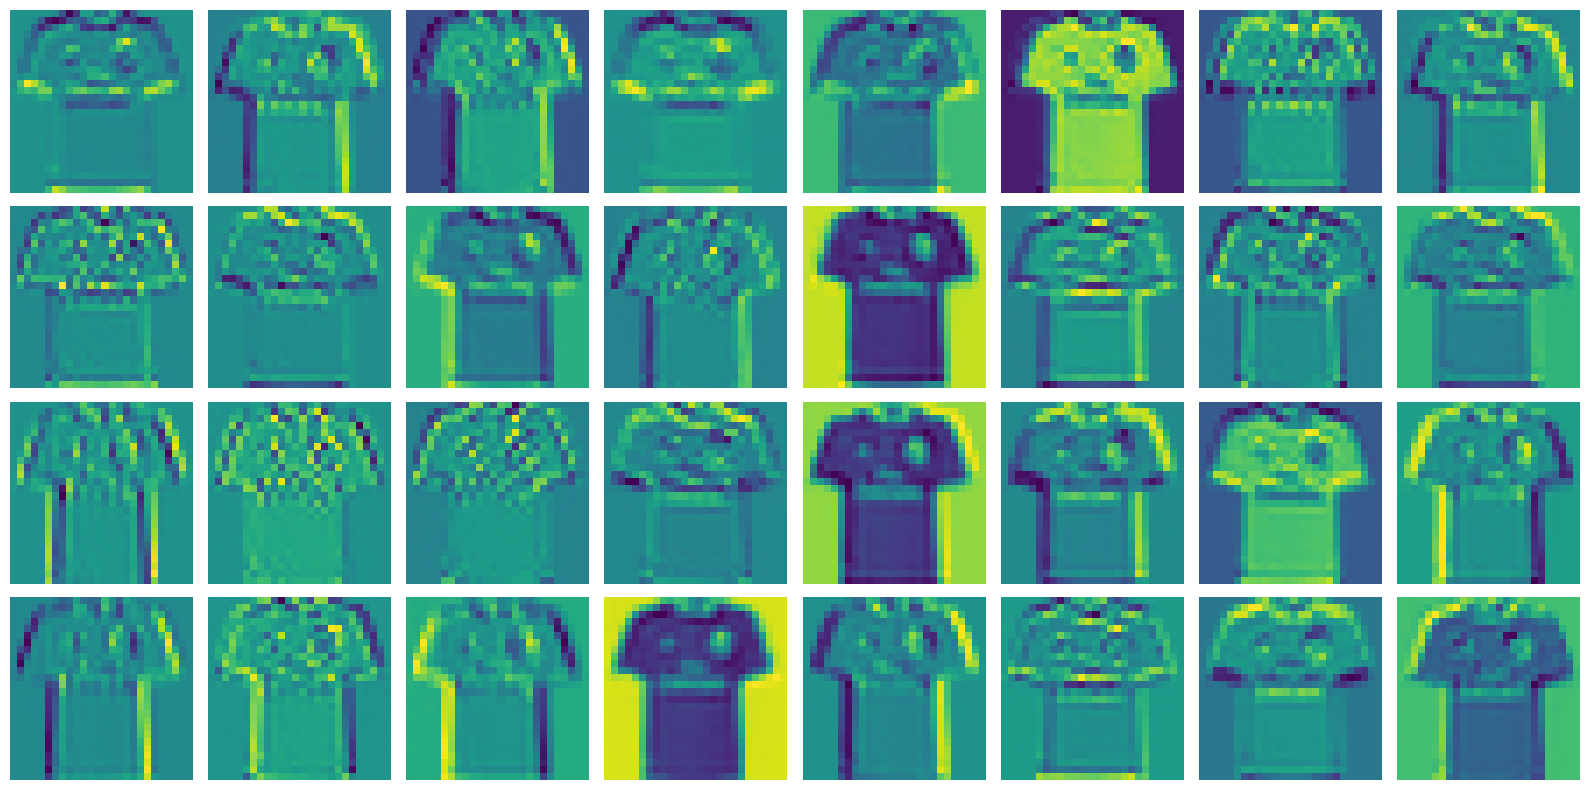

In [66]:
# Visualisasikan feature map dari layer konvolusi pertama model terbaik untuk satu gambar contoh.
# Buat model baru yang output-nya adalah output layer konvolusi pertama:
#   feature_model = keras.Model(inputs=model.inputs, outputs=model.layers[0].output)
# lalu tampilkan setiap channel hasil feature_model.predict() sebagai gambar.
# Apa saja pola yang ditangkap oleh masing-masing filter?
feature_model = tf.keras.Model(inputs=model_bn_do.inputs, outputs=model_bn_do.layers[0].output)

sample_image = X_test_cnn[0:1]
feature_maps = feature_model.predict(sample_image)

fig, axes = plt.subplots(4, 8, figsize=(16, 8))
axes = axes.ravel()

for i in range(32):
    axes[i].imshow(feature_maps[0, :, :, i], cmap='viridis')
    axes[i].axis('off')

plt.tight_layout()
plt.show()

Filter pada layer konvolusi pertama menangkap fitur visual tingkat rendah seperti garis tepi horizontal, garis tepi vertikal, sudut, serta kontur pencahayaan atau area gelap dan terang pada pakaian.

In [67]:
# Simpan model terbaik dengan model.save("model.keras").
# Model ini akan digunakan kembali pada tugas Deployment.
model_bn_do.save("model.keras")

# 5. Analisis


Eksperimen yang telah dilakukan membandingkan tiga arsitektur model neural network pada dataset Fashion-MNIST, yaitu Artificial Neural Network (ANN Baseline), Convolutional Neural Network (CNN Sederhana), serta CNN yang dilengkapi dengan Batch Normalization dan Dropout.

## Perbandingan Performa dan Pemrosesan Gambar
Model ANN memproses data gambar dengan meratakan matriks dua dimensi berukuran 28x28 piksel menjadi vektor satu dimensi sepanjang 784 elemen. Pendekatan perataan ini menghilangkan informasi hubungan spasial antarpiksel, seperti kedekatan piksel secara vertikal maupun horizontal. Akibatnya, ANN kesulitan mengenali pola visual yang kompleks dan menghasilkan tingkat akurasi terendah di antara ketiga model.

Sebaliknya, model CNN memproses gambar dalam bentuk matriks dua dimensi (28, 28, 1) menggunakan operasi konvolusi dan pooling. Layer konvolusi secara bertahap mengekstrak fitur spasial dari tingkat rendah seperti garis tepi dan sudut, hingga fitur tingkat tinggi seperti bentuk dan kontur pakaian. Pendekatan spasial ini membuat model CNN menghasilkan akurasi, presisi, recall, dan F1-score yang jauh lebih tinggi dibandingkan ANN.

## Hubungan Jumlah Parameter dan Efisiensi Model
Meskipun memiliki performa paling rendah, model ANN memiliki jumlah parameter paling besar, yaitu 235.146 parameter. Hal ini disebabkan oleh penggunaan Dense layer secara penuh dari 784 input ke 256 neuron yang membutuhkan 200.960 bobot hanya pada layer pertama.

Model CNN Sederhana justru memiliki jumlah parameter yang lebih sedikit, yaitu 225.034 parameter. Efisiensi ini diperoleh berkat mekanisme bobot terbagi (weight sharing) pada kernel konvolusi. Kernel konvolusi berukuran kecil (3x3) digeser ke seluruh area gambar untuk mendeteksi fitur yang sama tanpa memerlukan bobot terpisah untuk setiap lokasi piksel.

Model CNN dengan Batch Normalization dan Dropout memiliki total 225.418 parameter. Penambahan 384 parameter berasal dari variabel trainable dan non-trainable (mean, variance, gamma, beta) pada dua layer Batch Normalization.

## Pengaruh Batch Normalization dan Dropout terhadap Learning Curve
Pada pelatihan model CNN Sederhana, kurva akurasi dan loss pada data latih terus meningkat drastis mendekati nilai sempurna, namun kurva pada data validasi cenderung mendatar. Hal ini mengindikasikan terjadinya gejala overfitting, di mana model terlalu menghafal detail data latih sehingga kurang mampu melakukan generalisasi pada data baru.

Penerapan Batch Normalization menstabilkan distribusi aktivasi pada setiap layer konvolusi, yang mempercepat dan menstabilkan proses pembaruan bobot selama pelatihan. Tambahan layer Dropout dengan rate 0.5 sebelum layer output secara acak mematikan 50 persen neuron selama proses pelatihan. Mekanisme ini mencegah neuron saling bergantung secara berlebihan (co-adaptation). Hasilnya, celah antara kurva latih dan validasi pada model CNN dengan Batch Normalization dan Dropout menjadi jauh lebih rapat, menandakan bahwa overfitting berhasil diredam dengan baik.

## Analisis Kelas yang Sulit Dibedakan
Berdasarkan Confusion Matrix dari model terbaik, kelas yang paling sering mengalami kesalahan klasifikasi adalah kelas Shirt. Kelas Shirt sering kali diprediksi secara keliru sebagai T-shirt/top, Pullover, atau Coat.

Kesulitan klasifikasi pada kelompok ini disebabkan oleh kemiripan fitur visual secara fisik. Pakaian atasan tersebut memiliki kontur tubuh bagian atas yang sangat identik pada resolusi gambar grayscale 28x28 piksel. Detail kerah, kancing kemeja, atau tekstur kain sulit terdeteksi secara jelas pada resolusi rendah tersebut, sehingga model mengalami ambiguitas dalam membedakan kategori pakaian atasan tersebut.


# 6. Kesimpulan dan Saran


## Kesimpulan
1. Model berbasis Convolutional Neural Network (CNN) terbukti secara signifikan lebih unggul dibandingkan Artificial Neural Network (ANN) dalam memproses data citra Fashion-MNIST karena mampu mempertahankan hirarki spasial dua dimensi melalui layer konvolusi dan pooling.
2. Keunggulan CNN juga terlihat dari efisiensi parameternya, di mana CNN membutuhkan parameter lebih sedikit daripada ANN tetapi mampu menghasilkan performa evaluasi yang lebih tinggi berkat prinsip weight sharing.
3. Penambahan teknik regularisasi berupa Batch Normalization dan Dropout terbukti efektif menstabilkan proses pelatihan, merapatkan kurva pembelajaran antara data latih dan data validasi, serta mengurangi dampak overfitting pada model.
4. Tantangan utama klasifikasi pada dataset ini terletak pada perbedaan visual yang sangat tipis antar kategori pakaian atasan, khususnya antara kelas Shirt, T-shirt/top, Pullover, dan Coat.

## Saran
1. Menerapkan teknik Data Augmentation seperti rotasi sudut kecil, pergeseran horizontal atau vertikal, serta zoom acak untuk menambah variasi visual data latih, khususnya pada kelas-kelas pakaian atasan yang sering tertukar.
2. Melakukan eksperimen tuning hyperparameter lebih lanjut, seperti menguji variasi nilai rate Dropout (misalnya 0.2 hingga 0.4), mencoba optimizer lain seperti AdamW, atau mengimplementasikan learning rate scheduler untuk mencapai konvergensi yang lebih optimal.
3. Mencoba arsitektur jaringan yang lebih dalam atau menggunakan arsitektur residual (ResNet) sederhana apabila ingin meningkatkan kemampuan model dalam membedakan tekstur dan detail halus pada citra.